In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt

0.32

In [17]:
ticker = yf.Ticker("KO")

info = ticker.info

for clave, valor in info.items():
  print(f"{clave}: {valor}")
  
print(info.get('dividendRate'))


address1: One Coca-Cola Plaza
city: Atlanta
state: GA
zip: 30313
country: United States
phone: 404 676 2121
website: https://www.coca-colacompany.com
industry: Beverages - Non-Alcoholic
industryKey: beverages-non-alcoholic
industryDisp: Beverages - Non - Alcoholic
sector: Consumer Defensive
sectorKey: consumer-defensive
sectorDisp: Consumer Defensive
longBusinessSummary: The Coca-Cola Company, a beverage company, manufactures and sells various nonalcoholic beverages in the United States and internationally. The company provides Trademark Coca-Cola, sparkling soft drinks and flavors; water, sports, coffee, and tea; juice, value-added dairy, and plant-based beverages; and emerging beverages. It also offers beverage concentrates and syrups, as well as fountain syrups to fountain retailers comprising restaurants and convenience stores. The company sells its products under the Coca-Cola, Diet Coke/Coca-Cola Light, Coca-Cola Zero Sugar, caffeine free Diet Coke, Cherry Coke, Fanta, Sprite, Si

In [ ]:
# Extrae los datos fundamentales de la empresa.

eps = info.get("trailingEps")
sector = info.get("sector")
fcf = info.get("freeCashflow")
totalDebt = info.get("totalDebt")
totalCash = info.get("totalCash")
ebitda = info.get("ebitda")
payoutRatio = round(float(info.get("payoutRatio")),2) * 100
roe = info.get("returnOnEquity")
marketCap = info.get("marketCap")

# Divident Yield:
dividend_rate = info.get("dividendRate", 0)
price = info.get("currentPrice") or info.get("regularMarketPrice")
dividend_yield = round((dividend_rate / price) * 100, 2) if price else None



print(f"EPS: {eps} | Sector: {sector} | Divident Yield: % {dividend_yield} | Payout Ratio: % {payoutRatio}\nEbitda: {ebitda} | FreeCashFlow: {fcf} | Deuda Total {totalDebt} | ROE: {roe}")

EPS: 3.33 | Sector: Consumer Defensive | Divident Yield: % 2.28 | Payout Ratio: % 62.0
Ebitda: 16997999616 | FreeCashFlow: 5218749952 | Deuda Total 44260999168 | ROE: 0.42054


In [50]:
# Metricas compuestas.

net_debt = totalDebt - totalCash
anos_deuda = round((net_debt / fcf), 2)
fcf_yield = round(((fcf / marketCap)*100),2)

print(net_debt)
print(anos_deuda)
print(fcf_yield)

27889998848
5.34
1.3


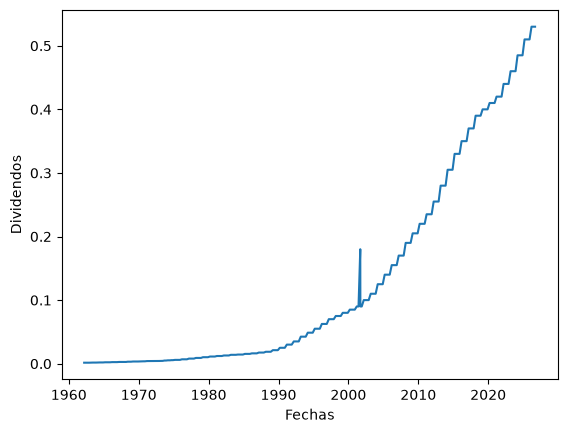

In [15]:
# Grafica el crecimiento del dividendo en el tiempo.

dividendos = ticker.dividends
fechas = list(dividendos.index)
valores_dividendos = list(dividendos)

plt.plot(fechas, valores_dividendos)
plt.xlabel("Fechas")
plt.ylabel("Dividendos")

plt.show()